SSTA & MLD Fig v2 整理过后的版本

In [2]:
import numpy as np
import xarray as xr
import pandas as pd
import netCDF4 as nc
import sacpy as scp                     
import matplotlib.pyplot as plt  

In [3]:
file_SST=r"C:/Users/Sebastian/Desktop/data/HadISST_sst.nc"
file_MLD=r"C:\Users\Sebastian\Desktop\data\reNZ_1980_2022_mld.nc"

In [4]:
a=xr.open_dataset(file_SST)
a=a.sst[:,::-1,:]
a1=a.loc['1980-01':'2022-12',-60:-17.5,140.5:179.5]
a2=a.loc['1980-01':'2022-12',-60:-17.5,-179.5:-130.5]
a2_new=xr.where(a2<0,np.nan,a2)
a1_new=xr.where(a1<0,np.nan,a1)
a1_new_lat=a1_new.latitude
a1_new_lon=a1_new.longitude
a1_new_time=a1_new.time
a2_new_lat=a2_new.latitude
a2_new_lon=np.arange(180.5,230,1)
a2_new_time=a2_new.time
a2_numpy=np.array(a2_new)
a2_xr_newlon=xr.DataArray(a2_numpy,coords=[a2_new_time,a2_new_lat,a2_new_lon],dims=['time','latitude','longitude'])
SST=xr.concat([a1_new,a2_xr_newlon],dim='longitude')#合并之后有一些nan点 不知道是不是因为是陆地呢
lon_SST=SST.longitude-360
SST=SST.loc['1981-12':'2023-02',-60:-17,140:230]

In [5]:
SSTA=scp.get_anom(SST,method=0)
SSTA_gb=SSTA.groupby('time.month')
SSTA_gb_JAN=np.array(SSTA_gb[1])
SSTA_gb_Feb=np.array(SSTA_gb[2])
SSTA_gb_Dec=np.array(SSTA_gb[12])
SSTA_STD_JAN=np.std(SSTA_gb_JAN,axis=0)
SSTA_STD_Feb=np.std(SSTA_gb_Feb,axis=0)
SSTA_STD_Dec=np.std(SSTA_gb_Dec,axis=0)


In [6]:
SSTA_STD_DJF=np.std(SSTA.groupby('time.season')['DJF'],axis=0)
SSTA_STD_DJF

c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


<xarray.DataArray 'sst' (latitude: 43, longitude: 90)>
array([[0.38100663, 0.40992212, 0.4471677 , ..., 0.57903713, 0.5660406 ,
        0.5505934 ],
       [0.3686965 , 0.38919786, 0.39245102, ..., 0.6081823 , 0.6195649 ,
        0.59345186],
       [0.3549866 , 0.37174043, 0.3680502 , ..., 0.6351698 , 0.65210116,
        0.62110513],
       ...,
       [       nan,        nan,        nan, ..., 0.30346218, 0.32628945,
        0.34938598],
       [       nan,        nan,        nan, ..., 0.3486111 , 0.37484914,
        0.39640236],
       [0.22791669,        nan,        nan, ..., 0.39285395, 0.41991088,
        0.44335008]], dtype=float32)
Coordinates:
  * latitude   (latitude) float32 -59.5 -58.5 -57.5 -56.5 ... -19.5 -18.5 -17.5
  * longitude  (longitude) float64 140.5 141.5 142.5 143.5 ... 227.5 228.5 229.5

In [7]:
lon=SST.longitude
lat=SST.latitude
Lon,Lat=np.meshgrid(lon,lat)

In [8]:
mld=xr.open_dataset(file_MLD)

In [9]:
mld=mld.dbss_obml

In [10]:
mld=mld.loc['1981-12':'2023-02',:,:]

In [11]:
mld_gb=mld.groupby('time.month')

In [12]:
mld_JAN=np.array(mld_gb[1])
mld_Feb=np.array(mld_gb[2])
mld_Dec=np.array(mld_gb[12])

In [13]:
mld_season=mld.groupby('time.season').mean()

In [14]:
import matplotlib.pyplot as plt###引入库包 
import cartopy.crs as ccrs  
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER 
import matplotlib.ticker as mticker 
from mpl_toolkits.axes_grid1.inset_locator import mark_inset 
import cartopy.feature as cfeature 
from matplotlib.patches import Rectangle

In [15]:
from matplotlib.colors import ListedColormap#调色用的

In [16]:
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.ticker as ticker

In [17]:
mld

<xarray.DataArray 'dbss_obml' (time: 493, latitude: 43, longitude: 90)>
[1907910 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 1981-12-01 1982-01-01 ... 2022-12-01
  * longitude  (longitude) float32 140.5 141.5 142.5 143.5 ... 227.5 228.5 229.5
  * latitude   (latitude) float32 -59.5 -58.5 -57.5 -56.5 ... -19.5 -18.5 -17.5
Attributes: (12/14)
    long_name:                Geometric Depth Below Sea Surface
    units:                    m
    dataset:                  NCEP GODAS
    var_desc:                 ocean mixed layer depth below sea surface
    level_desc:               unknown
    statistic:                Monthly Mean
    ...                       ...
    center:                   US National Weather Service - NCEP (WMC)
    level_indicator:          237
    gds_grid_type:            0
    parameter_table_version:  129
    parameter_number:         195
    actual_range:             [   5.111084 2718.8179  ]

c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:307: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:343: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


<Figure size 7000x8000 with 0 Axes>

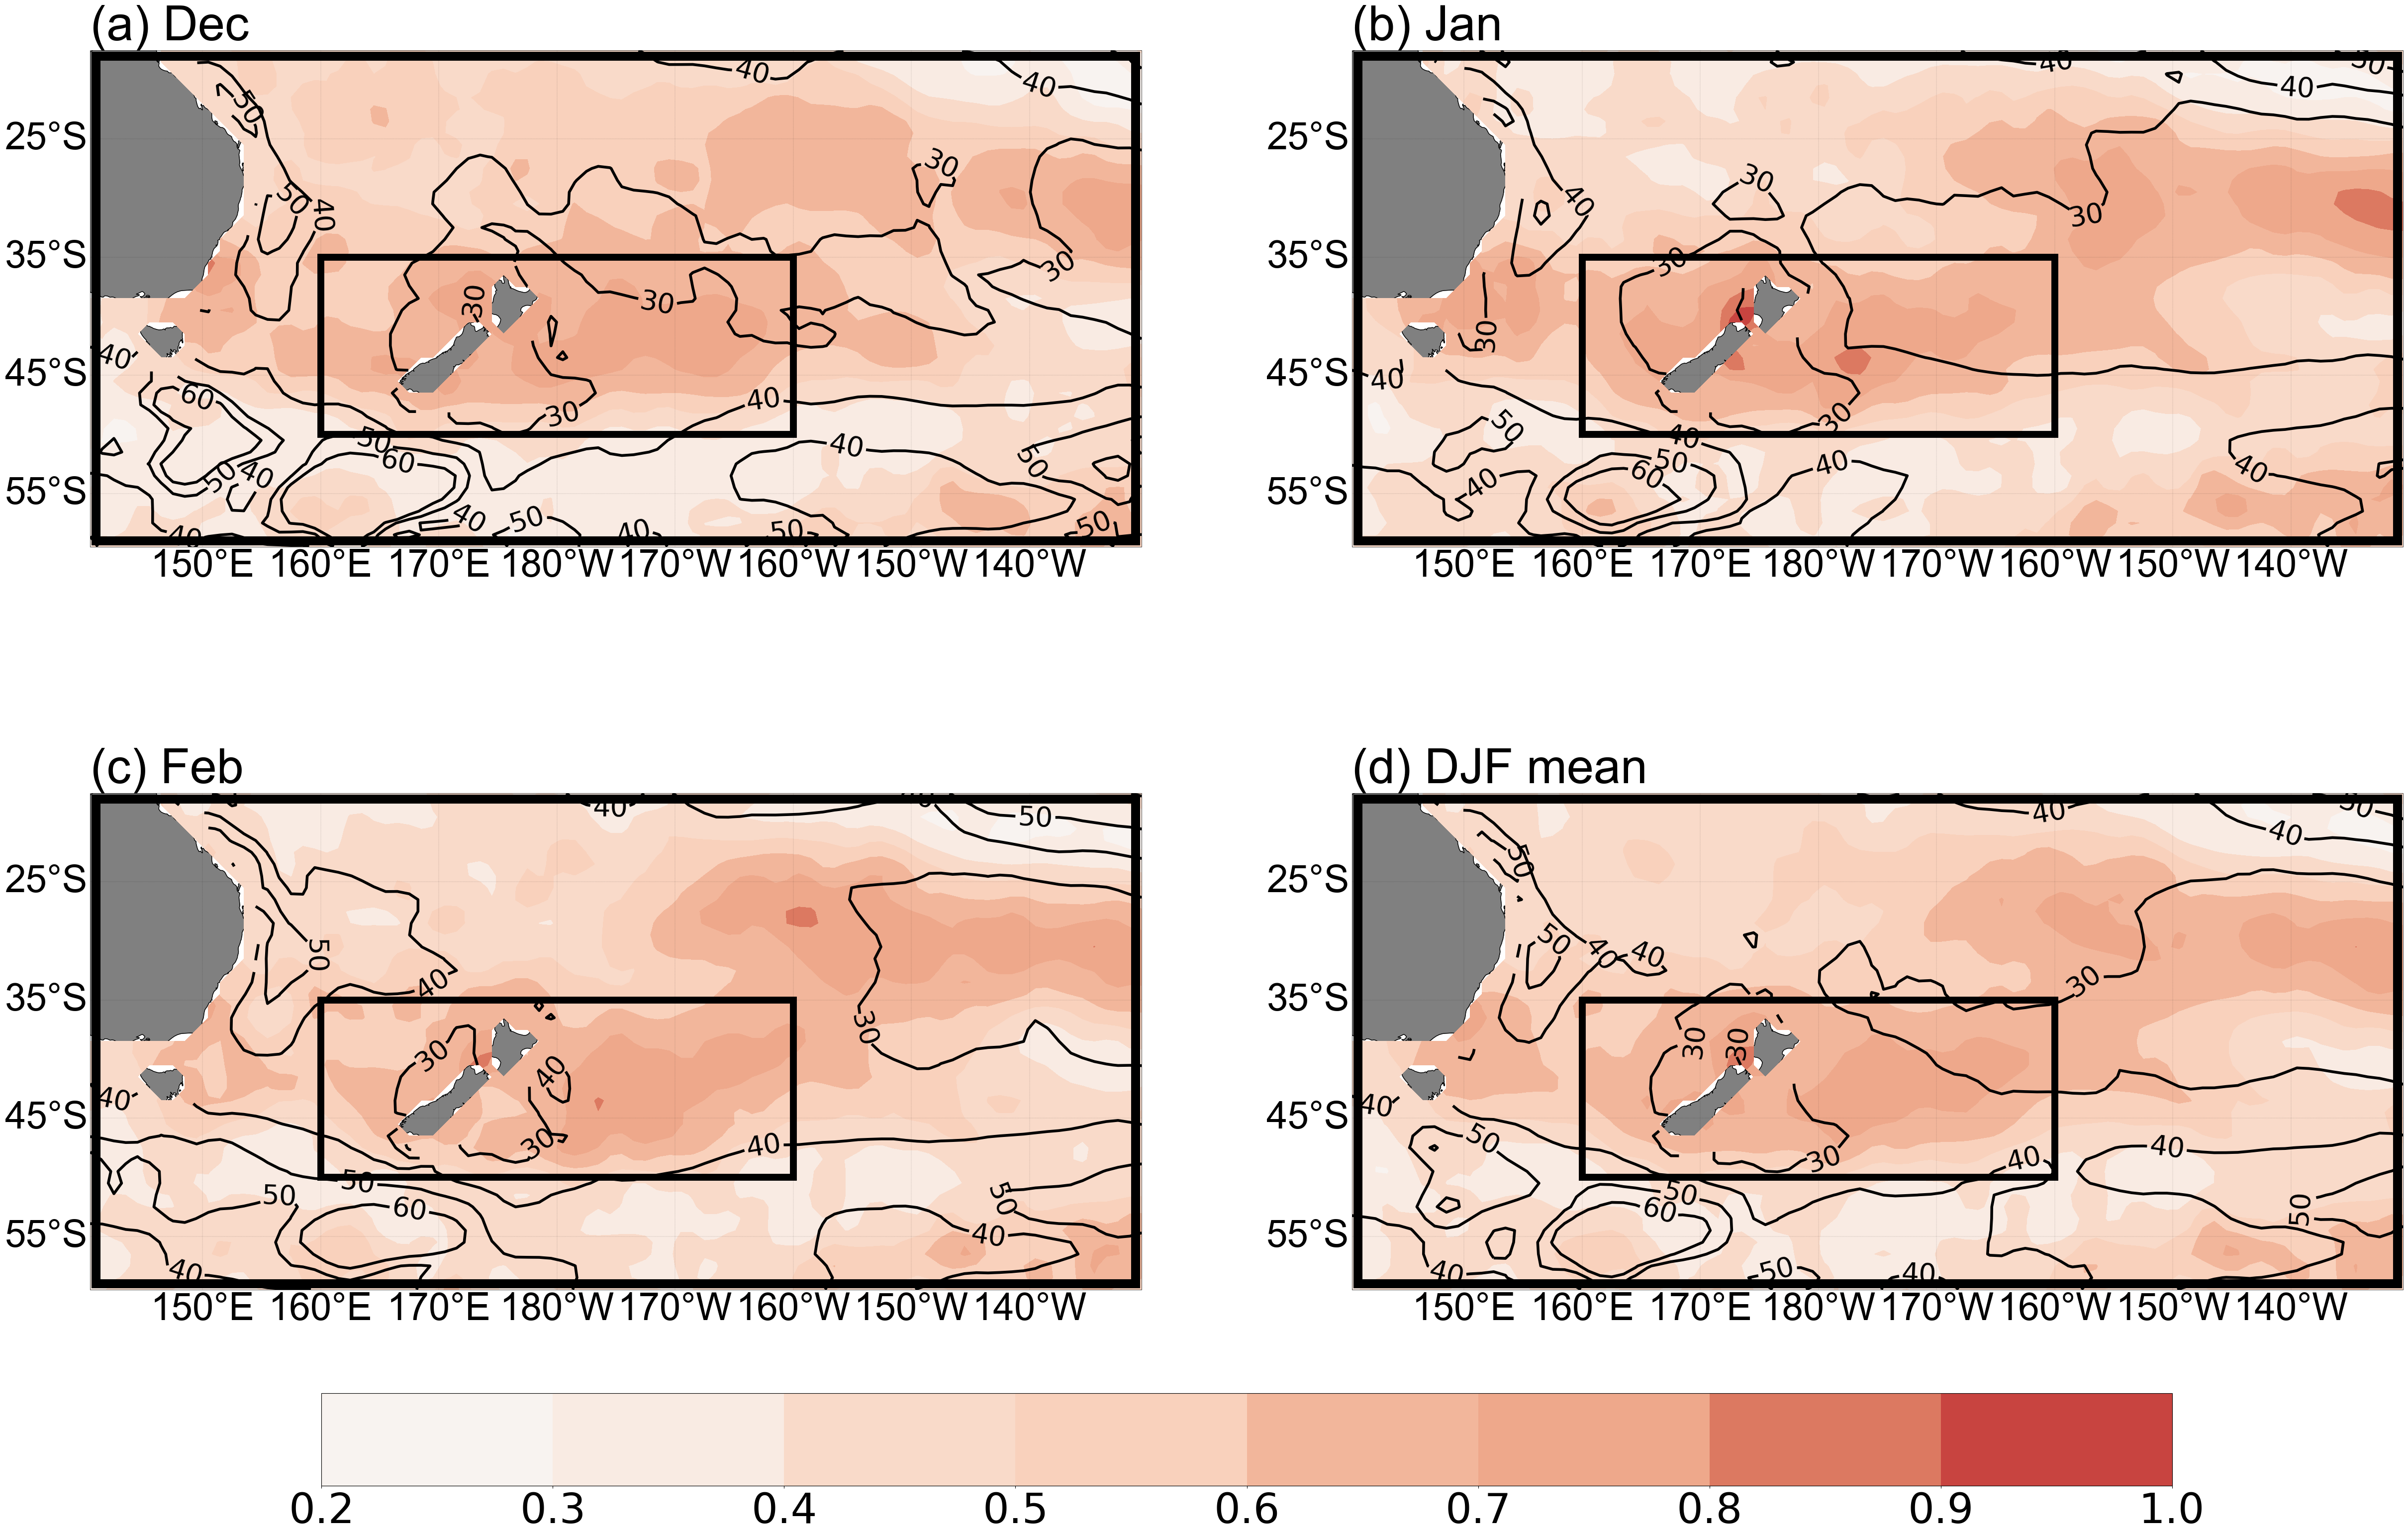

In [18]:
plt.figure(figsize=[70,80])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(60,45),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
outline_point=(141,-59)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

RE_4=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_5=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_6=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_7=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        ax[i][j].spines['geo'].set_linewidth(0.5)
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        #gl.xlabel_style = {'size': 32, "color": 'k'}     
        #gl.ylabel_style = {'size': 32, "color": 'k'}
        #gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(135,180,15),np.arange(-180,-130,5)]))
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(130,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {'size':55,'family':'Arial'}
        gl.ylabel_style = {'size':55,'family':'Arial'}

ax[0][0].tick_params(axis='x', length=10)

# 创建粉红色系的颜色列表
#colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
#colors = ['#fed470','#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
#colors = ['#FFA59E','#FF827D','#FF5F5F','#DE3941','#B70026']
#colors =[ '#e98b6e', '#e27c62', '#da6d57', '#d25d4d', '#ca4c43', '#b53438', '#ab2733', '#9c1e2e', '#8d162a', '#7e0c25', '#700320']
colors=['#fffac0','#FDEEA4','#fee289','#FECF6E','#febb56','#fe8c3c', '#fe8c3c', '#e66c36', '#cb4c31', '#af2c2c', '#910026']

colors=['#fad684', '#fbc26a', '#fcac53', '#f59747', '#ee823d', '#e66c36', '#d25432', '#bd3d2f', '#a8242b', '#910026']
colors=['#fcd5c5', '#f4bba7', '#eba18b','#e28772', '#d76c5b', '#d05c4f', '#c84c44', '#c03a3a','#ba3236', '#b42a31', '#ae202d', '#a81529']
colors = ['#f8f3f0', '#f3d7c9', '#ecbba5', '#e59e85', '#dd8068', '#d8705b', '#d25f4f', '#cc4d44', '#c94741', '#c6413e', '#c23a3b', '#bf3338']
colors = ['#f8f3f0', '#f9ebe3', '#f9e2d5', '#f9dac9', '#f9d1bc', '#f6c3ab', '#f2b69b', '#eea88b', '#e59175', '#dc7961', '#d2604f', '#c84440']

 #fcd5c5, #f4bba7, #eba18b, #e28772, #d76c5b, #d05c4f, #c84c44, #c03a3a, #ba3236, #b42a31, #ae202d, #a81529);
#fe8c3c, #e66c36, #cb4c31, #af2c2c, #910026
#'#fffac0','#FDEEA4',

# 创建颜色映射
cmap = ListedColormap(colors)

# 设置颜色映射范围
vmin, vmax = 0.2, 1
# 创建颜色映射
levels = np.linspace(vmin, vmax, 9)
norm = BoundaryNorm(levels, cmap.N)


ax[0][0].contourf(Lon,Lat,SSTA_STD_Dec,levels=levels,norm=norm, cmap=cmap,transform=ccrs.PlateCarree(0))
c=ax[0][1].contourf(Lon,Lat,SSTA_STD_JAN,levels=levels,norm=norm, cmap=cmap,transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,SSTA_STD_Feb,levels=levels, norm=norm,cmap=cmap,transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lon,Lat,SSTA_STD_DJF,levels=levels,norm=norm,cmap=cmap,transform=ccrs.PlateCarree(0))



e=ax[0][0].contour(Lon,Lat,mld_Dec.mean(axis=0),[30,40,50,60],transform=ccrs.PlateCarree(0),colors='black')
f=ax[0][1].contour(Lon,Lat,mld_JAN.mean(axis=0),[30,40,50,60],transform=ccrs.PlateCarree(0),colors='black')
g=ax[1][0].contour(Lon,Lat,mld_Feb.mean(axis=0),[30,40,50,60],transform=ccrs.PlateCarree(0),colors='black')
d=ax[1][1].contour(Lon,Lat,mld_season[0,:,:],[30,40,50,60],transform=ccrs.PlateCarree(0),colors='black')

for contour in e.collections:
    contour.set_linewidth(4)

for contour in f.collections:
    contour.set_linewidth(4)

for contour in g.collections:
    contour.set_linewidth(4)

for contour in d.collections:
    contour.set_linewidth(4)


ax[0][0].set_title('(a) Dec',fontsize=70,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=70,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=70,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=70,fontname='Arial',loc='left')



ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)
#用添加矩形框的方式增加边框
ax[0][0].add_patch(RE_4)
ax[0][1].add_patch(RE_5)
ax[1][0].add_patch(RE_6)
ax[1][1].add_patch(RE_7)




ax[0][0].tick_params(axis='x',pad=50)

RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)
RE_4.set_linewidth(13)
RE_5.set_linewidth(13)
RE_6.set_linewidth(13)
RE_7.set_linewidth(13)



cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type: ignore
                      orientation='horizontal', shrink=0.8,pad=0.06)
font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
plt.clabel(d,fontsize=40,colors='black')
plt.clabel(e,fontsize=40,colors='black')
plt.clabel(f,fontsize=40,colors='black')
plt.clabel(g,fontsize=40,colors='black')


#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=60,pad=4)

<Figure size 7000x8000 with 0 Axes>

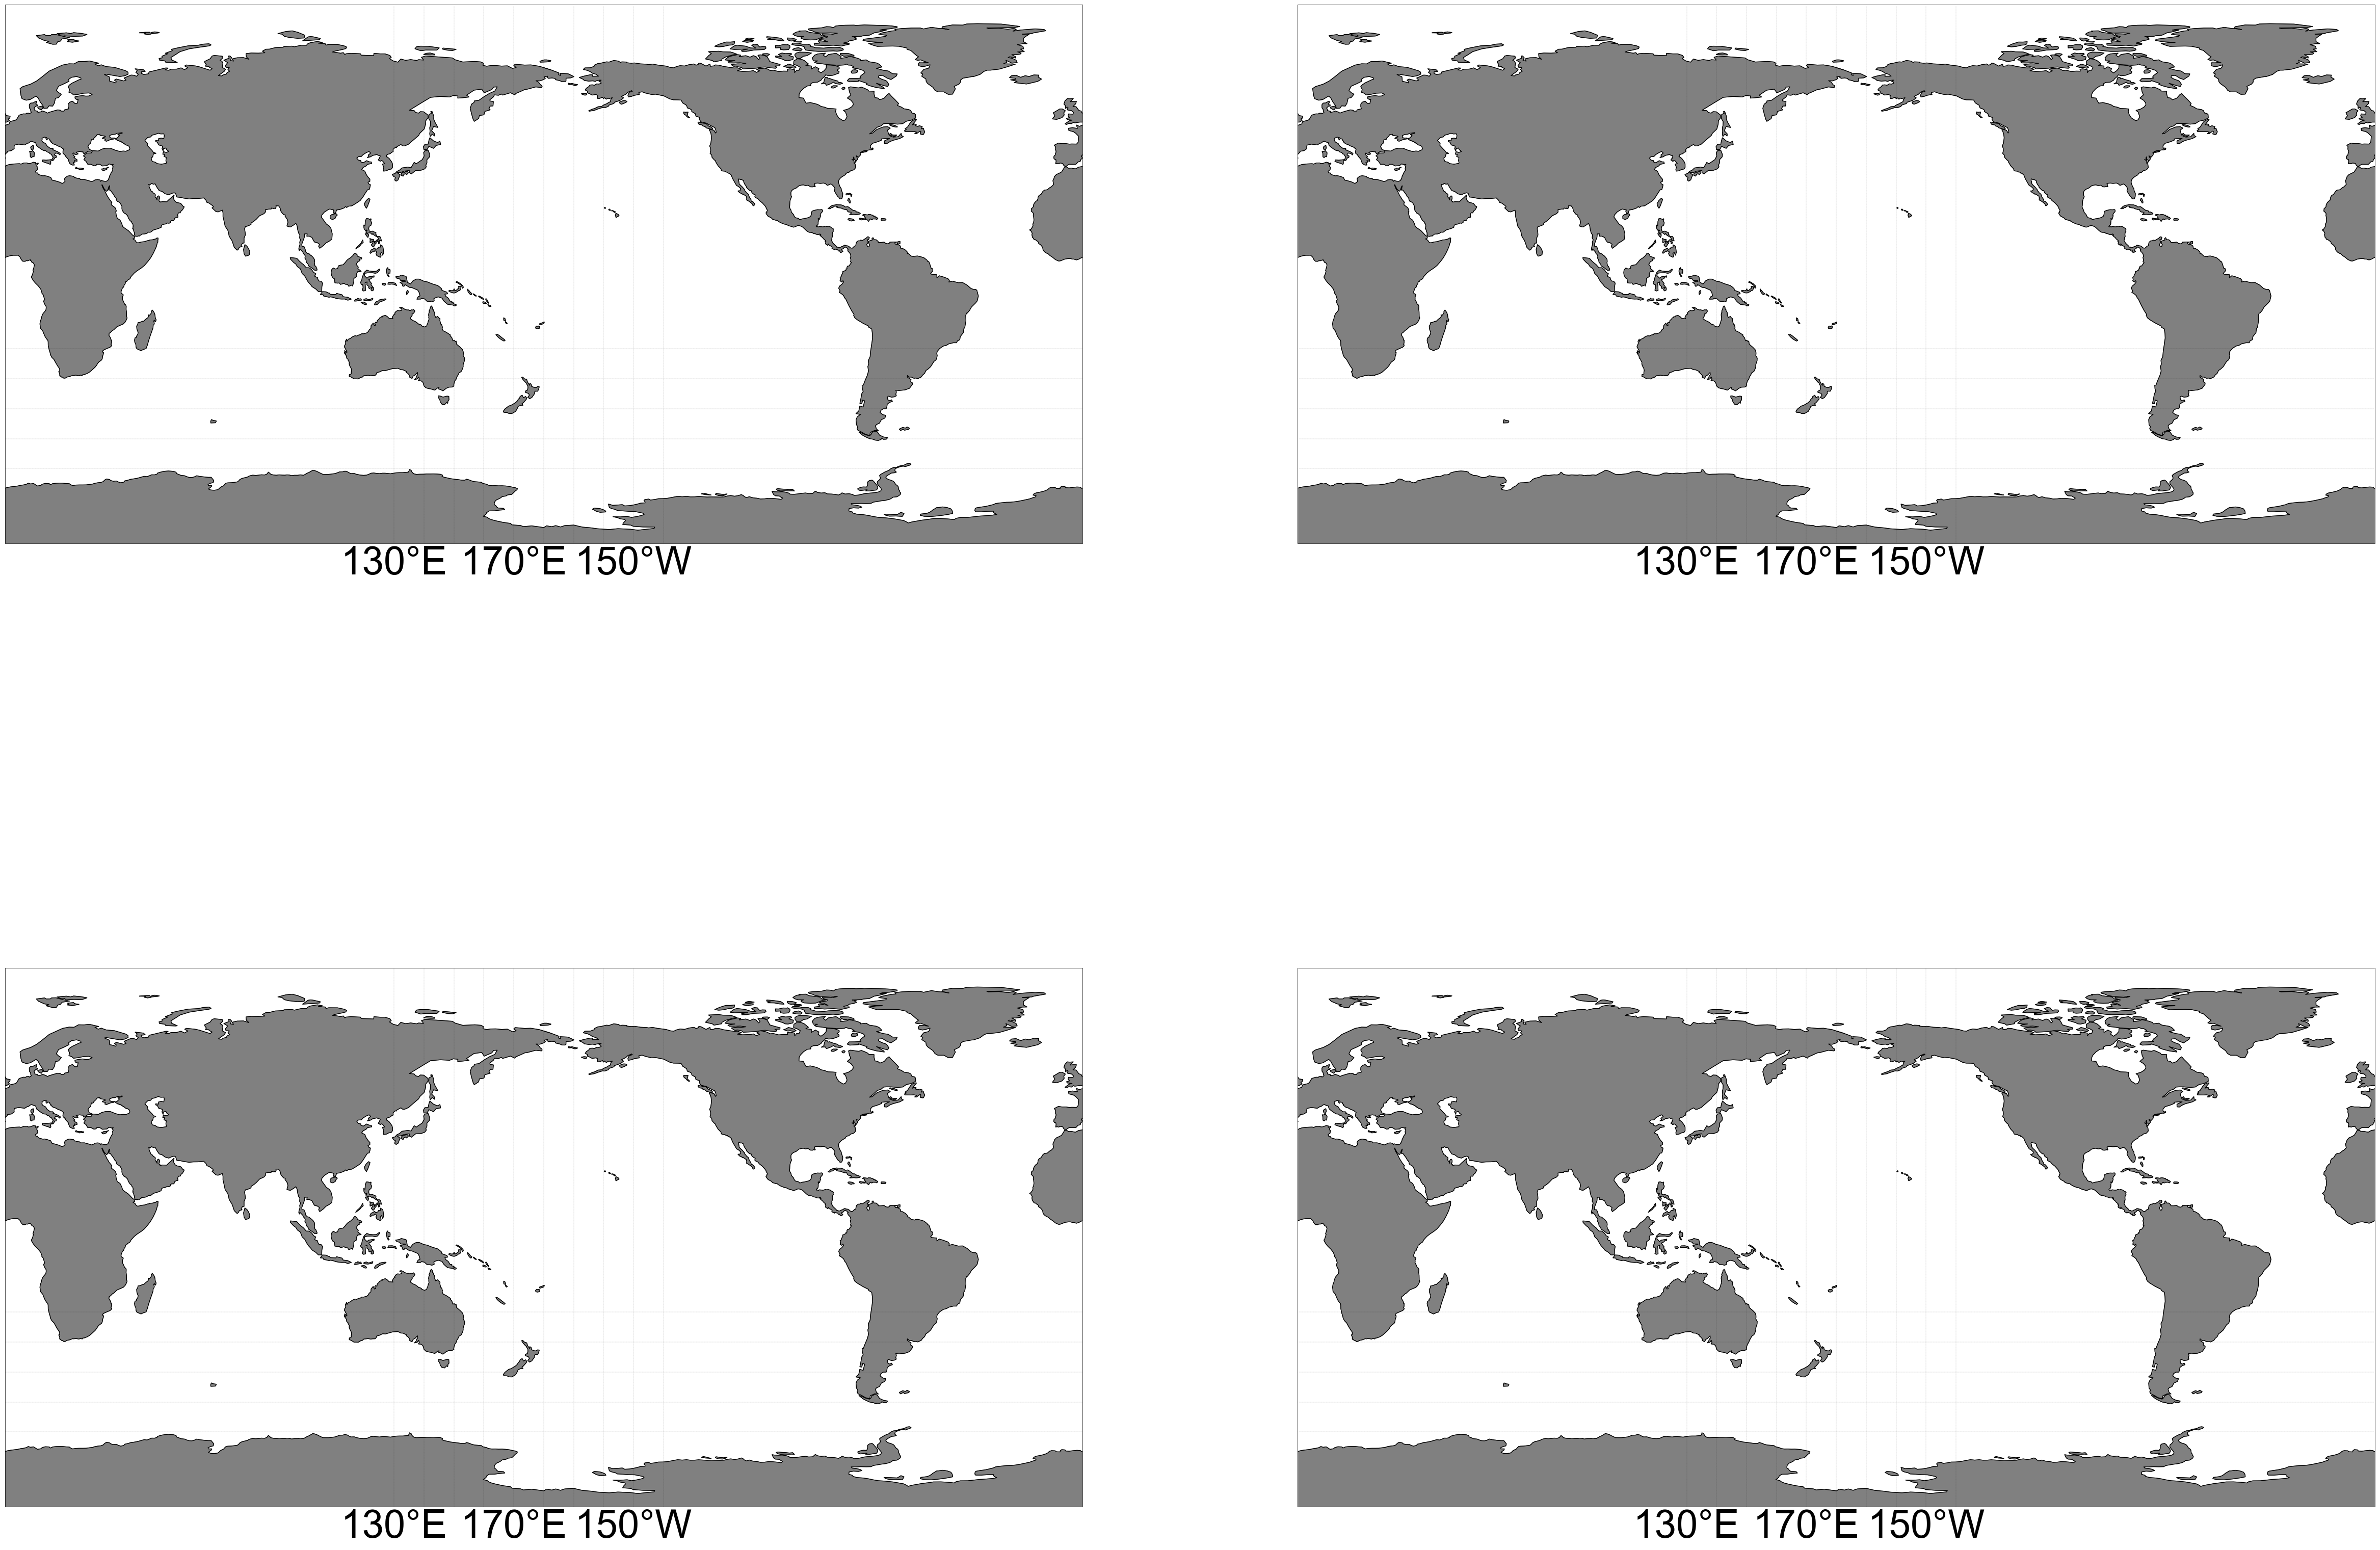

In [19]:
plt.figure(figsize=[70,80])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(60,45),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
outline_point=(141,-59)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

RE_4=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_5=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_6=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE_7=Rectangle(outline_point,229.5-141.5,-18+59,linewidth=8,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        ax[i][j].spines['geo'].set_linewidth(0.5)
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        #gl.xlabel_style = {'size': 32, "color": 'k'}     
        #gl.ylabel_style = {'size': 32, "color": 'k'}
        #gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(135,180,15),np.arange(-180,-130,5)]))
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(130,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {'size':55,'family':'Arial'}
        gl.ylabel_style = {'size':55,'family':'Arial'}
        
ax[0][0].tick_params(axis='x',pad=50)


In [17]:
SSTA_STD_DJF

<xarray.DataArray 'sst' (latitude: 43, longitude: 90)>
array([[0.38100663, 0.40992212, 0.4471677 , ..., 0.57903713, 0.5660406 ,
        0.5505934 ],
       [0.3686965 , 0.38919786, 0.39245102, ..., 0.6081823 , 0.6195649 ,
        0.59345186],
       [0.3549866 , 0.37174043, 0.3680502 , ..., 0.6351698 , 0.65210116,
        0.62110513],
       ...,
       [       nan,        nan,        nan, ..., 0.30346218, 0.32628945,
        0.34938598],
       [       nan,        nan,        nan, ..., 0.3486111 , 0.37484914,
        0.39640236],
       [0.22791669,        nan,        nan, ..., 0.39285395, 0.41991088,
        0.44335008]], dtype=float32)
Coordinates:
  * latitude   (latitude) float32 -59.5 -58.5 -57.5 -56.5 ... -19.5 -18.5 -17.5
  * longitude  (longitude) float64 140.5 141.5 142.5 143.5 ... 227.5 228.5 229.5

In [18]:
SSTA_STD_DJF_xr=xr.DataArray(SSTA_STD_DJF,coords=[SSTA.latitude,SSTA.longitude],dims=['lat','lon'])

In [19]:
SSTA_STD_DJF[np.where(SSTA_STD_DJF==0.8638697)]

<xarray.DataArray 'sst' (latitude: 1, longitude: 1)>
array([[0.8638697]], dtype=float32)
Coordinates:
  * latitude   (latitude) float32 -40.5
  * longitude  (longitude) float64 173.5

c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:307: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:343: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


<Figure size 7000x8000 with 0 Axes>

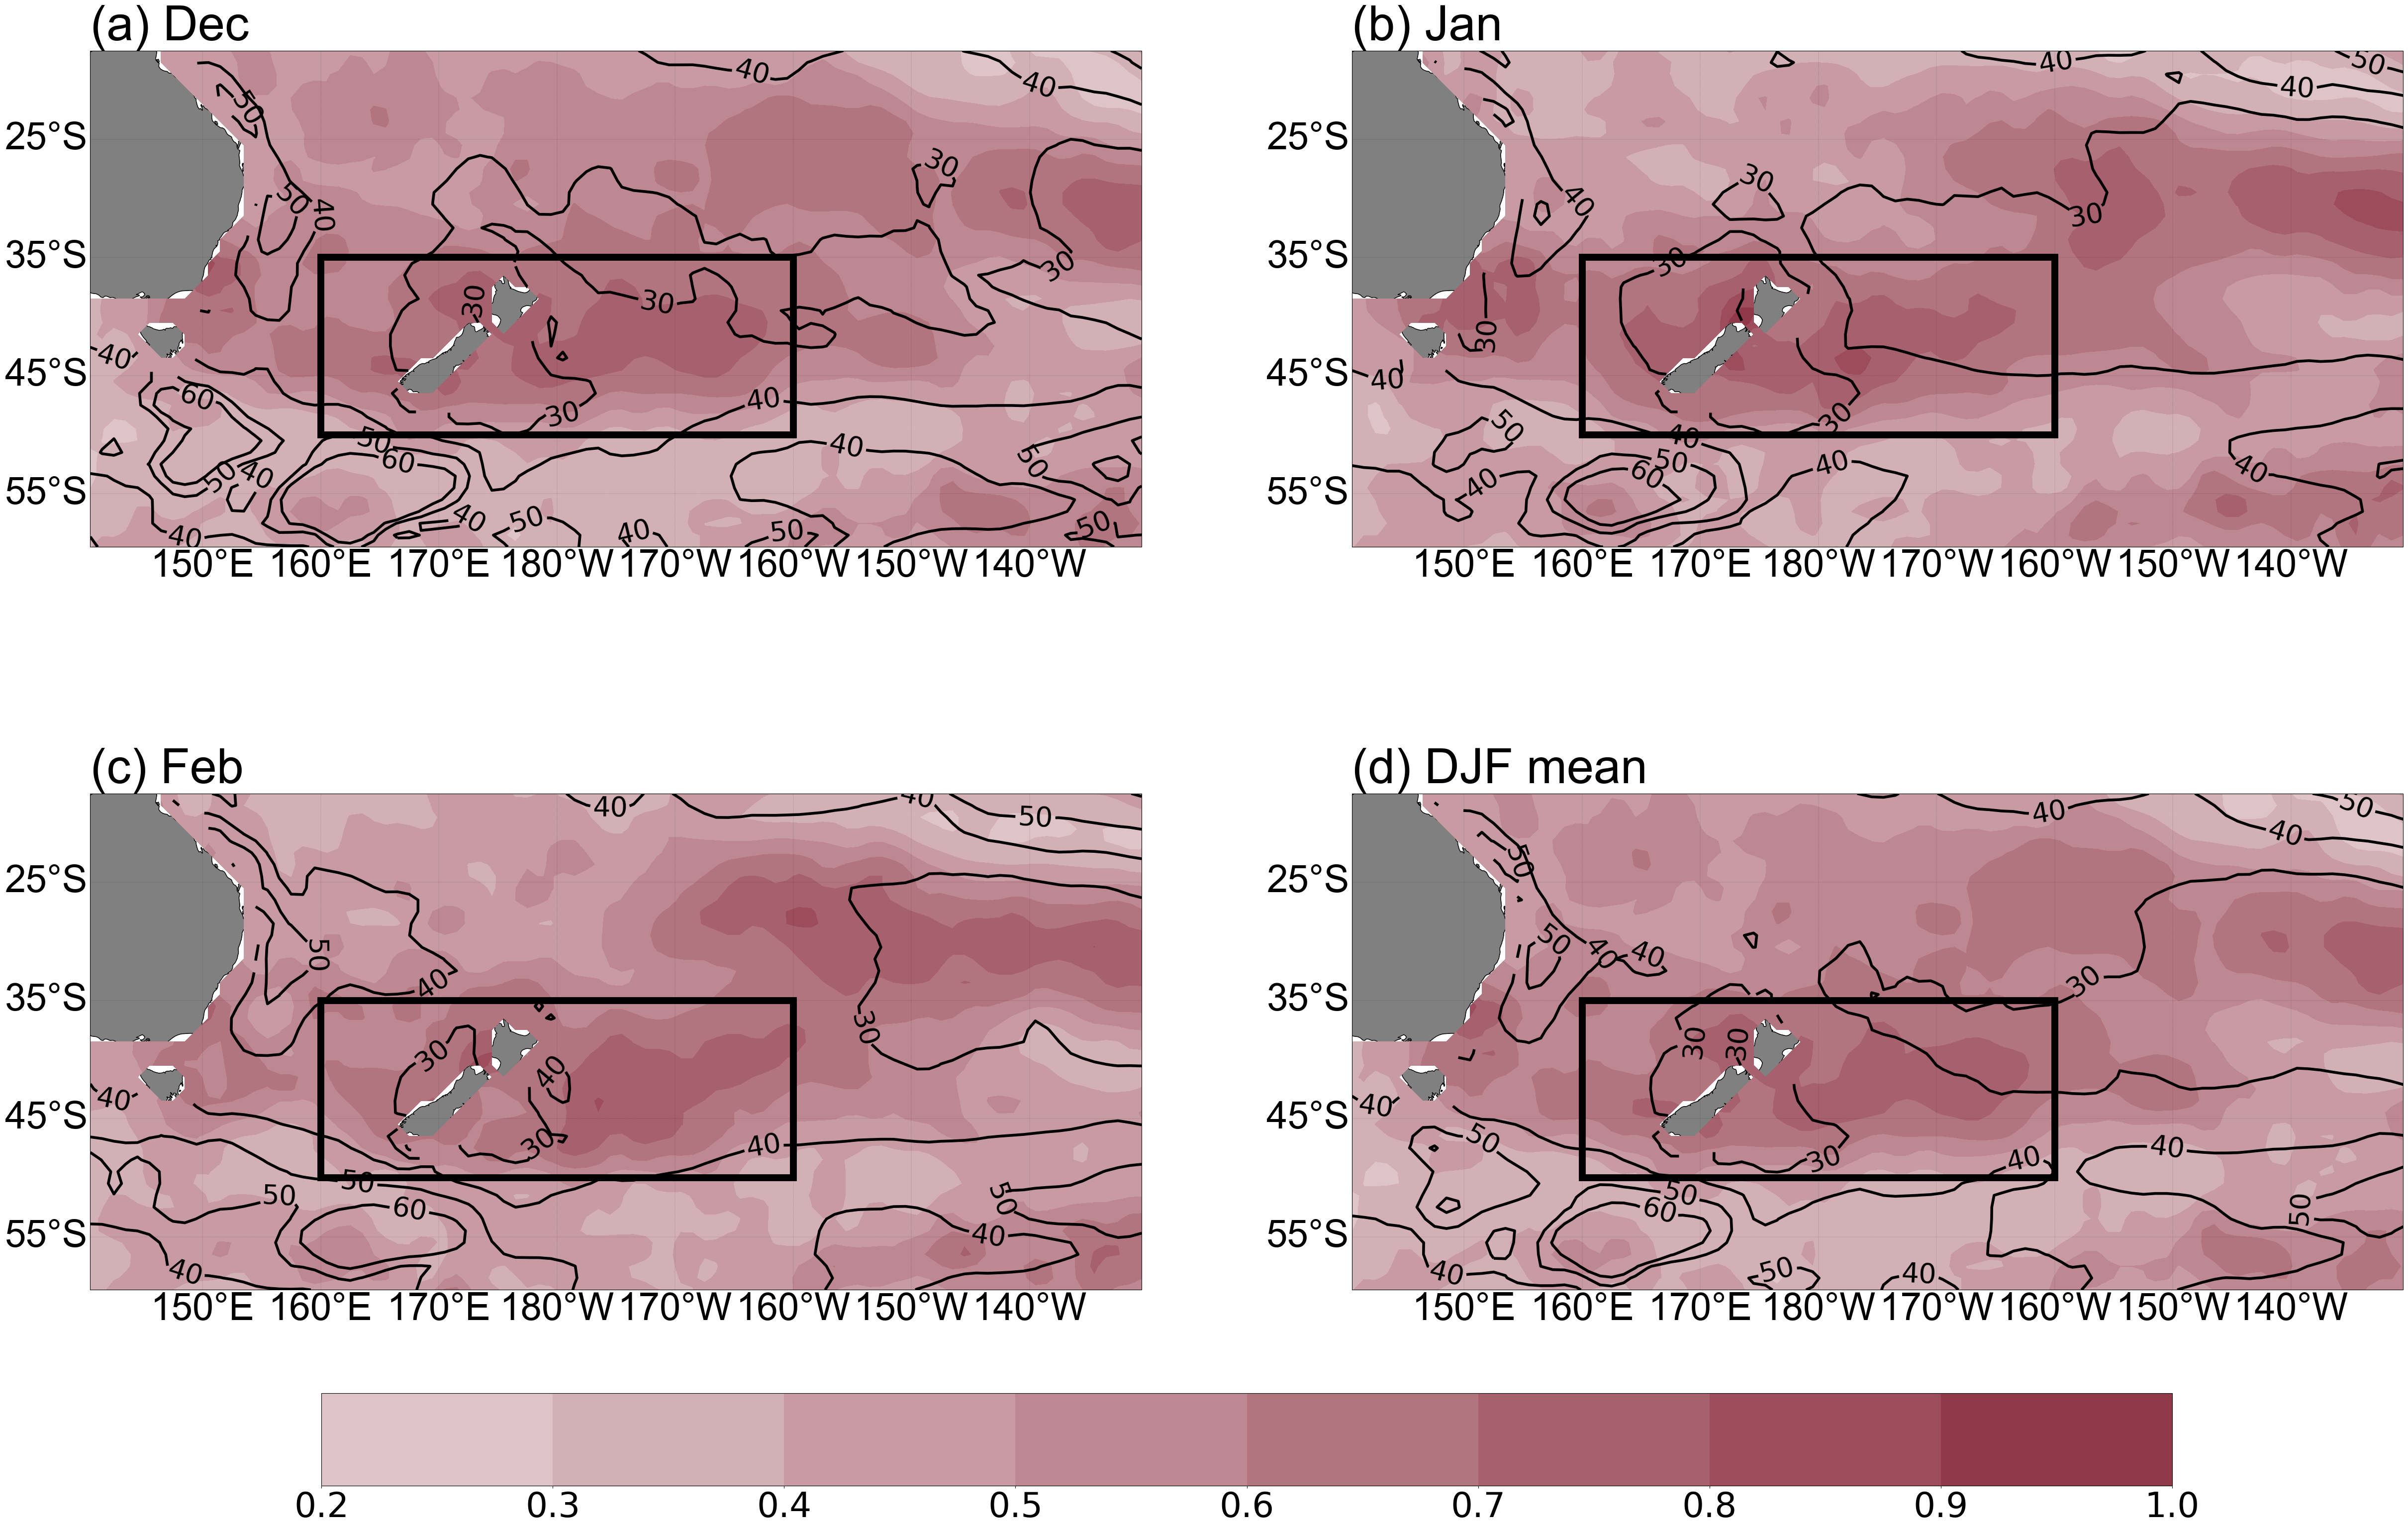

In [20]:
plt.figure(figsize=[70,80])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(60,45),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25



for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        #gl.xlabel_style = {'size': 32, "color": 'k'}     
        #gl.ylabel_style = {'size': 32, "color": 'k'}
        #gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(135,180,15),np.arange(-180,-130,5)]))
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(130,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.xlabel_style = {'size':55,'family':'Arial'}
        gl.ylabel_style = {'size':55,'family':'Arial'}
# 创建粉红色系的颜色列表
#colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
#colors = ['#fed470','#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
#colors = ['#FFA59E','#FF827D','#FF5F5F','#DE3941','#B70026']
#colors =[ '#e98b6e', '#e27c62', '#da6d57', '#d25d4d', '#ca4c43', '#b53438', '#ab2733', '#9c1e2e', '#8d162a', '#7e0c25', '#700320']
colors=['#fffac0','#FDEEA4','#fee289','#FECF6E','#febb56','#fe8c3c', '#fe8c3c', '#e66c36', '#cb4c31', '#af2c2c', '#910026']

colors=['#fad684', '#fbc26a', '#fcac53', '#f59747', '#ee823d', '#e66c36', '#d25432', '#bd3d2f', '#a8242b', '#910026']
colors=['#fcd5c5', '#f4bba7', '#eba18b','#e28772', '#d76c5b', '#d05c4f', '#c84c44', '#c03a3a','#ba3236', '#b42a31', '#ae202d', '#a81529']
colors = ['#f8f3f0', '#f3d7c9', '#ecbba5', '#e59e85', '#dd8068', '#d8705b', '#d25f4f', '#cc4d44', '#c94741', '#c6413e', '#c23a3b', '#bf3338']
colors = ['#f8f3f0', '#f9ebe3', '#f9e2d5', '#f9dac9', '#f9d1bc', '#f6c3ab', '#f2b69b', '#eea88b', '#e59175', '#dc7961', '#d2604f', '#c84440']

colors=['#dec3c8','#d3afb6','#c89ba4','#bd8891','#b2747f','#a7606d','#9c4c5b','#913849']
# 创建颜色映射
cmap = ListedColormap(colors)

# 设置颜色映射范围
vmin, vmax = 0.2, 1
# 创建颜色映射
levels = np.linspace(vmin, vmax, 9)
norm = BoundaryNorm(levels, cmap.N)


ax[0][0].contourf(Lon,Lat,SSTA_STD_Dec,levels=levels,norm=norm, cmap=cmap,transform=ccrs.PlateCarree(0))
c=ax[0][1].contourf(Lon,Lat,SSTA_STD_JAN,levels=levels,norm=norm, cmap=cmap,transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,SSTA_STD_Feb,levels=levels, norm=norm,cmap=cmap,transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lon,Lat,SSTA_STD_Dec,levels=levels,norm=norm,cmap=cmap,transform=ccrs.PlateCarree(0))



e=ax[0][0].contour(Lon,Lat,mld_Dec.mean(axis=0),[30,40,50,60],transform=ccrs.PlateCarree(0),colors='black')
f=ax[0][1].contour(Lon,Lat,mld_JAN.mean(axis=0),[30,40,50,60],transform=ccrs.PlateCarree(0),colors='black')
g=ax[1][0].contour(Lon,Lat,mld_Feb.mean(axis=0),[30,40,50,60],transform=ccrs.PlateCarree(0),colors='black')
d=ax[1][1].contour(Lon,Lat,mld_season[0,:,:],[30,40,50,60],transform=ccrs.PlateCarree(0),colors='black')

for contour in e.collections:
    contour.set_linewidth(4)

for contour in f.collections:
    contour.set_linewidth(4)

for contour in g.collections:
    contour.set_linewidth(4)

for contour in d.collections:
    contour.set_linewidth(4)


ax[0][0].set_title('(a) Dec',fontsize=70,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=70,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=70,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=70,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)

ax[0][0].tick_params(axis='x',pad=50)

RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type: ignore
                      orientation='horizontal', shrink=0.8,pad=0.06)
font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
plt.clabel(d,fontsize=40,colors='black')
plt.clabel(e,fontsize=40,colors='black')
plt.clabel(f,fontsize=40,colors='black')
plt.clabel(g,fontsize=40,colors='black')
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=50)